# Healthy Compounder 候補は comp_ew に上乗せできるか

`01_univariate` で、Healthy Compounder の統合スコア `hc_all` は単独では `comp_ew` の半分程度の強さ（IC 0.038 vs 0.065）だった。
一方で `comp_ew` との順位相関は 0.29 と低く、回転率も半分（192% vs 402%/年）。採用の判断は単独の強さではなく **comp_ew にどれだけ上乗せできるか** で決める。

確認すること:

1. **残差 IC**: 各月 `comp_ew` に回帰した残差にまだ予測力があるか
2. **スパニング回帰**: 各スコアの Q5 − Q1 リターンを `comp_ew` の Q5 − Q1 で説明したときにアルファが残るか
3. **複合**: `comp_ew` × `hc_all` を 90:10 / 80:20 / 70:30 で混ぜたときの指標（いつもの評価）
4. **中立化版**: `hc_all` は低ボラ・大型に傾いており（BM 加重平均 +0.27、QMJ 安全性は +0.49）、AI スコアと同じく最適化の制約で吸収される恐れがある。
   サイズ・`vola60`・セクターで中立化した `hc_all_neu` でも同じ比較をする

スコアの生成コマンド（実行済み）:

```bash
uv run python scripts/build_healthy_compounder.py
uv run python scripts/build_neutralize.py --score hc/hc_all --size --sector --controls core/vola60 --name hc_all_neu --group hc_neu --start 200801 --end 202606
uv run python scripts/build_blend.py --score-a composite/comp_ew --score-b hc/hc_all --weights 90 80 70 --name "comp_ew_{a}_hc_{b}" --group composite --start 200801 --end 202606
uv run python scripts/build_blend.py --score-a composite/comp_ew --score-b hc_neu/hc_all_neu --weights 90 80 70 --name "comp_ew_{a}_hcneu_{b}" --group composite --start 200801 --end 202606
```

**規約**: `01_univariate` と同じ（Q5 = 最上位、drtn 複利 / srtn 累和、税は信託・INR、コスト 15/25bp、バーンイン 12 か月、BM = MSCI India、2008-01 以降）。

In [1]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # noqa: F401  日本語ラベル用
import numpy as np
import pandas as pd
from scipy.stats import norm

from alphaeval import InputStore, compute_alpha_report, ic_summary, india_tax_schedule, information_coefficient, plot_cross_alpha_bars, plot_cumulative, quantile_analysis, summary_table
from alphaeval.panel import forward_returns

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
HC = ["hc_all", "hc_all_neu", "hc_cash", "hc_qmj", "hc_sales_stab", "hc_issuance", "hc_cfoa", "hc_cfp", "hc_dso", "hc_qmj_prof", "hc_qmj_growth", "hc_qmj_safety", "hc_qmj_payout"]
HC_PATH = {n: ("hc_neu/hc_all_neu" if n == "hc_all_neu" else f"hc/{n}") for n in HC}
W = [90, 80, 70]
BLENDS = [f"comp_ew_{w}_hc_{100 - w}" for w in W] + [f"comp_ew_{w}_hcneu_{100 - w}" for w in W]
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
RETURN_KINDS = {"drtn": "rtn", "srtn": "srtn"}
START, END = 200801, 202606
N_QUANTILES = 5
CW_MAX_WEIGHT = 0.05
COST_BUY, COST_SELL = 0.0015, 0.0025
FPI_TYPE = "trust"
BURN_IN = 12

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
load = lambda path: store.alpha(path, START, END).reindex(index=univ.index, columns=univ.columns).where(univ.notna())
scores = {"comp_ew": load("composite/comp_ew"), **{n: load(p) for n, p in HC_PATH.items()}, **{n: load(f"composite/{n}") for n in BLENDS}}
returns = {kind: store.returns(RISK_MODEL, col, START, 202607) for kind, col in RETURN_KINDS.items()}
fwd = {kind: forward_returns(r, 1) for kind, r in returns.items()}


def blom(values: pd.DataFrame) -> pd.DataFrame:
    ranks = values.rank(axis=1)
    n = values.notna().sum(axis=1)
    return pd.DataFrame(norm.ppf(ranks.sub(0.375).div(n + 0.25, axis=0).to_numpy(dtype=float)), index=values.index, columns=values.columns)


def residualize(y: pd.DataFrame, x: pd.DataFrame) -> pd.DataFrame:
    # 各月、Blom(y) を定数 + Blom(x) に OLS 回帰した残差（両方そろう銘柄のみ）
    m = y.notna() & x.notna()
    yb, xb = blom(y.where(m)), blom(x.where(m))
    yc = yb.sub(yb.mean(axis=1), axis=0)
    xc = xb.sub(xb.mean(axis=1), axis=0)
    beta = (yc * xc).sum(axis=1) / (xc**2).sum(axis=1)
    return yc - xc.mul(beta, axis=0)

## 1. 残差 IC（comp_ew に回帰した残差の予測力）

各月、ユニバース内で Blom 化したスコアを Blom 化した `comp_ew` に回帰し、残差と翌月リターンの順位相関を取る。バーンイン後（2009-01 以降）。

In [2]:
rows = {}
for n in HC:
    s = scores[n]
    res = residualize(s, scores["comp_ew"])
    row = {"corr(comp_ew)": float(blom(s).corrwith(blom(scores["comp_ew"]), axis=1, method="spearman").mean())}
    for kind in ["drtn", "srtn"]:
        raw = ic_summary(information_coefficient(s, fwd[kind], univ).iloc[BURN_IN:])
        rr = ic_summary(information_coefficient(res, fwd[kind], univ).iloc[BURN_IN:])
        row.update({(f"{kind} IC"): raw["mean"], (f"{kind} t"): raw["t_stat"], (f"{kind} 残差 IC"): rr["mean"], (f"{kind} 残差 t"): rr["t_stat"], (f"{kind} 残差 ICIR"): rr["icir"]})
    rows[n] = row
resid_tbl = pd.DataFrame(rows).T
display(resid_tbl.round(3))

,corr(comp_ew),drtn IC,drtn t,drtn 残差 IC,drtn 残差 t,drtn 残差 ICIR,srtn IC,srtn t,srtn 残差 IC,srtn 残差 t,srtn 残差 ICIR
hc_all,0.291,0.038,4.092,0.021,2.701,0.186,0.024,3.713,0.014,2.399,0.166
hc_all_neu,0.260,0.020,4.043,0.004,0.780,0.054,0.008,1.805,-0.001,-0.316,-0.022
hc_cash,0.186,0.023,3.888,0.012,2.288,0.158,0.011,2.039,0.004,0.763,0.053
hc_qmj,0.221,0.031,2.496,0.017,1.532,0.106,0.023,2.777,0.015,1.916,0.132
hc_sales_stab,0.122,0.017,2.361,0.011,1.774,0.122,0.011,2.033,0.006,1.179,0.081
hc_issuance,0.234,0.027,4.669,0.013,2.381,0.164,0.017,3.078,0.008,1.415,0.098
hc_cfoa,0.284,0.032,3.038,0.015,1.636,0.113,0.021,2.884,0.011,1.634,0.113
hc_cfp,0.064,0.014,2.437,0.009,1.641,0.113,0.005,0.829,0.002,0.273,0.019
hc_dso,0.062,0.009,1.766,0.005,1.077,0.074,0.003,0.596,0.001,0.201,0.014
hc_qmj_prof,0.272,0.033,3.000,0.016,1.612,0.111,0.022,2.910,0.012,1.731,0.119


## 2. スパニング回帰（Q5 − Q1 リターン）

等ウェイト 5 分位の Q5 − Q1 月次リターンを `comp_ew` の Q5 − Q1 に回帰する: $r^{hc}_t = \alpha + \beta\, r^{comp}_t + \varepsilon_t$。
$\alpha$ は年率、t 値は Newey-West（ラグ 6）。$\alpha$ が有意なら `comp_ew` で説明できない収益源がある。

In [3]:
def nw_ols(y: pd.Series, x: pd.Series, lags: int = 6) -> dict[str, float]:
    df = pd.concat([y, x], axis=1).dropna()
    Y = df.iloc[:, 0].to_numpy()
    X = np.column_stack([np.ones(len(df)), df.iloc[:, 1].to_numpy()])
    b = np.linalg.lstsq(X, Y, rcond=None)[0]
    e = Y - X @ b
    xtx_inv = np.linalg.inv(X.T @ X)
    S = (X * e[:, None]).T @ (X * e[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (X[L:] * e[L:, None]).T @ (X[:-L] * e[:-L, None])
        S += w * (G + G.T)
    se = np.sqrt(np.diag(xtx_inv @ S @ xtx_inv))
    r2 = 1 - (e**2).sum() / ((Y - Y.mean()) ** 2).sum()
    return {"alpha (年率)": b[0] * 12, "alpha t": b[0] / se[0], "beta": b[1], "beta t": b[1] / se[1], "R2": r2, "月数": len(df)}

spreads = {kind: {} for kind in RETURN_KINDS}
for n in ["comp_ew"] + HC:
    for kind in RETURN_KINDS:
        q = quantile_analysis(scores[n], returns[kind], univ, N_QUANTILES)
        spreads[kind][n] = q.returns["spread"].iloc[BURN_IN:]
rows = {}
for n in HC:
    row = {}
    for kind in RETURN_KINDS:
        res = nw_ols(spreads[kind][n], spreads[kind]["comp_ew"])
        row.update({(kind, k): v for k, v in res.items() if k != "月数"})
        row[(kind, "Q5−Q1 (年率)")] = spreads[kind][n].mean() * 12
    rows[n] = row
span = pd.DataFrame(rows).T
span.columns = pd.MultiIndex.from_tuples(span.columns)
display(span.round(3))

drtn                                                srtn                                        
              alpha (年率) alpha t   beta  beta t     R2 Q5−Q1 (年率) alpha (年率) alpha t   beta beta t     R2 Q5−Q1 (年率)
hc_all            -0.029  -1.109  0.662  10.438  0.460      0.087     -0.002  -0.105  0.458  5.731  0.234      0.052
hc_all_neu         0.035   1.701  0.186   4.052  0.122      0.068      0.001   0.049  0.230  3.617  0.105      0.028
hc_cash            0.011   0.424  0.325   6.060  0.254      0.068      0.010   0.480  0.226  4.613  0.092      0.037
hc_qmj            -0.135  -3.865  0.889  10.424  0.492      0.021     -0.062  -2.577  0.589  5.547  0.255      0.007
hc_sales_stab     -0.073  -2.179  0.472   4.719  0.360      0.010     -0.018  -0.935  0.198  3.153  0.072      0.006
hc_issuance        0.028   1.125  0.197   3.902  0.106      0.062      0.026   1.138  0.099  1.547  0.017      0.037
hc_cfoa           -0.063  -2.348  0.741   9.765  0.532      0.068     -0.022  -1.123  0.544  6.088  0.313      0.041
hc_cfp             0.042   1.769  0.070   0.989  0.014      0.054      0.017   0.826  0.044  0.826  0.003      0.022
hc_dso             0.017   0.706  0.063   1.322  0.012      0.028     -0.008  -0.396  0.107  1.974  0.020      0.004
hc_qmj_prof       -0.073  -2.322  0.744  10.577  0.476      0.058     -0.034  -1.681  0.537  6.076  0.277      0.029
hc_qmj_growth     -0.080  -2.746  0.293   3.961  0.145     -0.028     -0.068  -3.438  0.283  3.520  0.097     -0.034
hc_qmj_safety     -0.182  -5.211  1.028  10.553  0.553     -0.001     -0.057  -2.178  0.537  5.303  0.241      0.006
hc_qmj_payout     -0.019  -0.967  0.369  10.292  0.359      0.046     -0.001  -0.051  0.270  5.114  0.157      0.031

## 3. 複合（comp_ew × hc_all / hc_all_neu）

### 3.1 スタイルへの傾き

BM 加重平均が大きいほど、ロングオンリー・対 BM 制約の最適化でアクティブに取りにくい。

In [4]:
def row_rank_corr(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    m = a.notna() & b.notna()
    ra, rb = a.where(m).rank(axis=1), b.where(m).rank(axis=1)
    ra, rb = ra.sub(ra.mean(axis=1), axis=0), rb.sub(rb.mean(axis=1), axis=0)
    return (ra * rb).sum(axis=1) / np.sqrt((ra**2).sum(axis=1) * (rb**2).sum(axis=1))

EVAL = ["comp_ew", "hc_all", "hc_all_neu"] + BLENDS
style = {"log size": np.log(univ.where(univ > 0)), **{c: store.alpha(f"core/{c}", START, END).reindex(index=univ.index, columns=univ.columns) for c in ["vola60", "mom12_1", "bp_act"]}}
bmw = bm.reindex(index=univ.index, columns=univ.columns)
rows = {}
for n in EVAL:
    s = scores[n]
    rows[n] = {**{f"corr({k})": float(row_rank_corr(s, v).mean()) for k, v in style.items()}, "corr(comp_ew)": float(row_rank_corr(s, scores["comp_ew"]).mean()), "BM 加重平均": float(((s * bmw).sum(axis=1) / bmw.where(s.notna()).sum(axis=1)).mean())}
display(pd.DataFrame(rows).T.round(3))

,corr(log size),corr(vola60),corr(mom12_1),corr(bp_act),corr(comp_ew),BM 加重平均
comp_ew,0.035,-0.154,0.595,-0.224,1.000,-0.126
hc_all,0.091,-0.392,0.058,-0.164,0.291,0.270
hc_all_neu,-0.002,-0.011,0.047,-0.059,0.260,-0.104
comp_ew_90_hc_10,0.044,-0.187,0.579,-0.231,0.994,-0.094
comp_ew_80_hc_20,0.053,-0.223,0.552,-0.237,0.975,-0.055
comp_ew_70_hc_30,0.063,-0.261,0.514,-0.240,0.936,-0.011
comp_ew_90_hcneu_10,0.033,-0.149,0.580,-0.221,0.994,-0.131
comp_ew_80_hcneu_20,0.031,-0.142,0.555,-0.216,0.974,-0.137
comp_ew_70_hcneu_30,0.028,-0.131,0.517,-0.206,0.934,-0.141


### 3.2 一括計算と指標表

In [5]:
schedule = india_tax_schedule(FPI_TYPE)
reports = {}
for n in EVAL:
    reports[n] = compute_alpha_report(n, scores[n], univ, bm, returns, n_quantiles=N_QUANTILES, cw_max_weight=CW_MAX_WEIGHT, tax_schedule=schedule, cost_buy=COST_BUY, cost_sell=COST_SELL, burn_in=BURN_IN, tax_kind="drtn")
    print(f"{n:22s} done")
tbl = summary_table(reports)
print("drtn（配当込みトータルリターン）")
display(tbl["drtn"].round(3))
print("srtn（固有リターン）")
display(tbl["srtn"].round(3))
display(tbl["共通"].round(3))
print("分位別の年率リターン（drtn、Q5 = 最上位）")
display(pd.DataFrame({n: rep.quantile_returns["drtn"].drop(columns="spread").mean() * 12 for n, rep in reports.items()}).T.round(3))

comp_ew                done


hc_all                 done


hc_all_neu             done


comp_ew_90_hc_10       done


comp_ew_80_hc_20       done


...

srtn（固有リターン）


指標,Q5 EW 超過 (vs BM),Q5 EW 超過 (vs BM) IR,Q5 − Q1,Q5 − Q1 IR,Q5 CW 超過 (vs BM),Q5 CW 超過 (vs BM) IR,税控除後 Q5 EW 超過 (vs BM),税控除後 Q5 EW 超過 (vs BM) IR,IC,ICIR,IC t
comp_ew,0.101,1.009,0.117,1.071,0.063,0.784,0.055,0.563,0.039,0.380,5.501
hc_all,0.057,0.691,0.052,0.497,0.026,0.464,0.029,0.362,0.024,0.256,3.713
hc_all_neu,0.052,0.508,0.028,0.358,0.027,0.361,0.022,0.226,0.008,0.125,1.805
comp_ew_90_hc_10,0.098,0.991,0.117,1.035,0.061,0.785,0.054,0.554,0.040,0.385,5.578
comp_ew_80_hc_20,0.092,0.970,0.111,0.984,0.051,0.711,0.049,0.526,0.041,0.389,5.633
comp_ew_70_hc_30,0.091,0.976,0.111,0.983,0.047,0.673,0.049,0.539,0.041,0.387,5.603
comp_ew_90_hcneu_10,0.095,0.959,0.113,1.047,0.058,0.731,0.052,0.531,0.039,0.379,5.495
comp_ew_80_hcneu_20,0.094,0.941,0.116,1.071,0.060,0.769,0.050,0.517,0.038,0.377,5.466
comp_ew_70_hcneu_30,0.091,0.910,0.101,0.949,0.055,0.696,0.050,0.508,0.037,0.370,5.358


指標,回転率 EW,回転率 CW,コストドラッグ,税ドラッグ,短期比率
comp_ew,4.022,4.169,0.017,0.028,0.809
hc_all,1.916,1.511,0.008,0.019,0.639
hc_all_neu,2.278,2.329,0.009,0.019,0.730
comp_ew_90_hc_10,3.903,4.040,0.016,0.027,0.782
comp_ew_80_hc_20,3.729,3.746,0.015,0.027,0.777
comp_ew_70_hc_30,3.488,3.454,0.014,0.026,0.760
comp_ew_90_hcneu_10,3.901,4.018,0.016,0.026,0.789
comp_ew_80_hcneu_20,3.780,3.878,0.016,0.026,0.785
comp_ew_70_hcneu_30,3.571,3.590,0.015,0.025,0.764


分位別の年率リターン（drtn、Q5 = 最上位）


,Q1,Q2,Q3,Q4,Q5
comp_ew,0.106,0.146,0.180,0.217,0.282
hc_all,0.139,0.185,0.197,0.190,0.226
hc_all_neu,0.156,0.197,0.173,0.189,0.223
comp_ew_90_hc_10,0.103,0.153,0.172,0.226,0.278
comp_ew_80_hc_20,0.102,0.147,0.179,0.230,0.274
comp_ew_70_hc_30,0.102,0.148,0.177,0.232,0.272
comp_ew_90_hcneu_10,0.103,0.153,0.175,0.224,0.277
comp_ew_80_hcneu_20,0.099,0.154,0.176,0.227,0.276
comp_ew_70_hcneu_30,0.109,0.146,0.173,0.229,0.273


### 3.3 混合比率と指標

横軸は comp_ew の重み（100% = comp_ew 単独）。

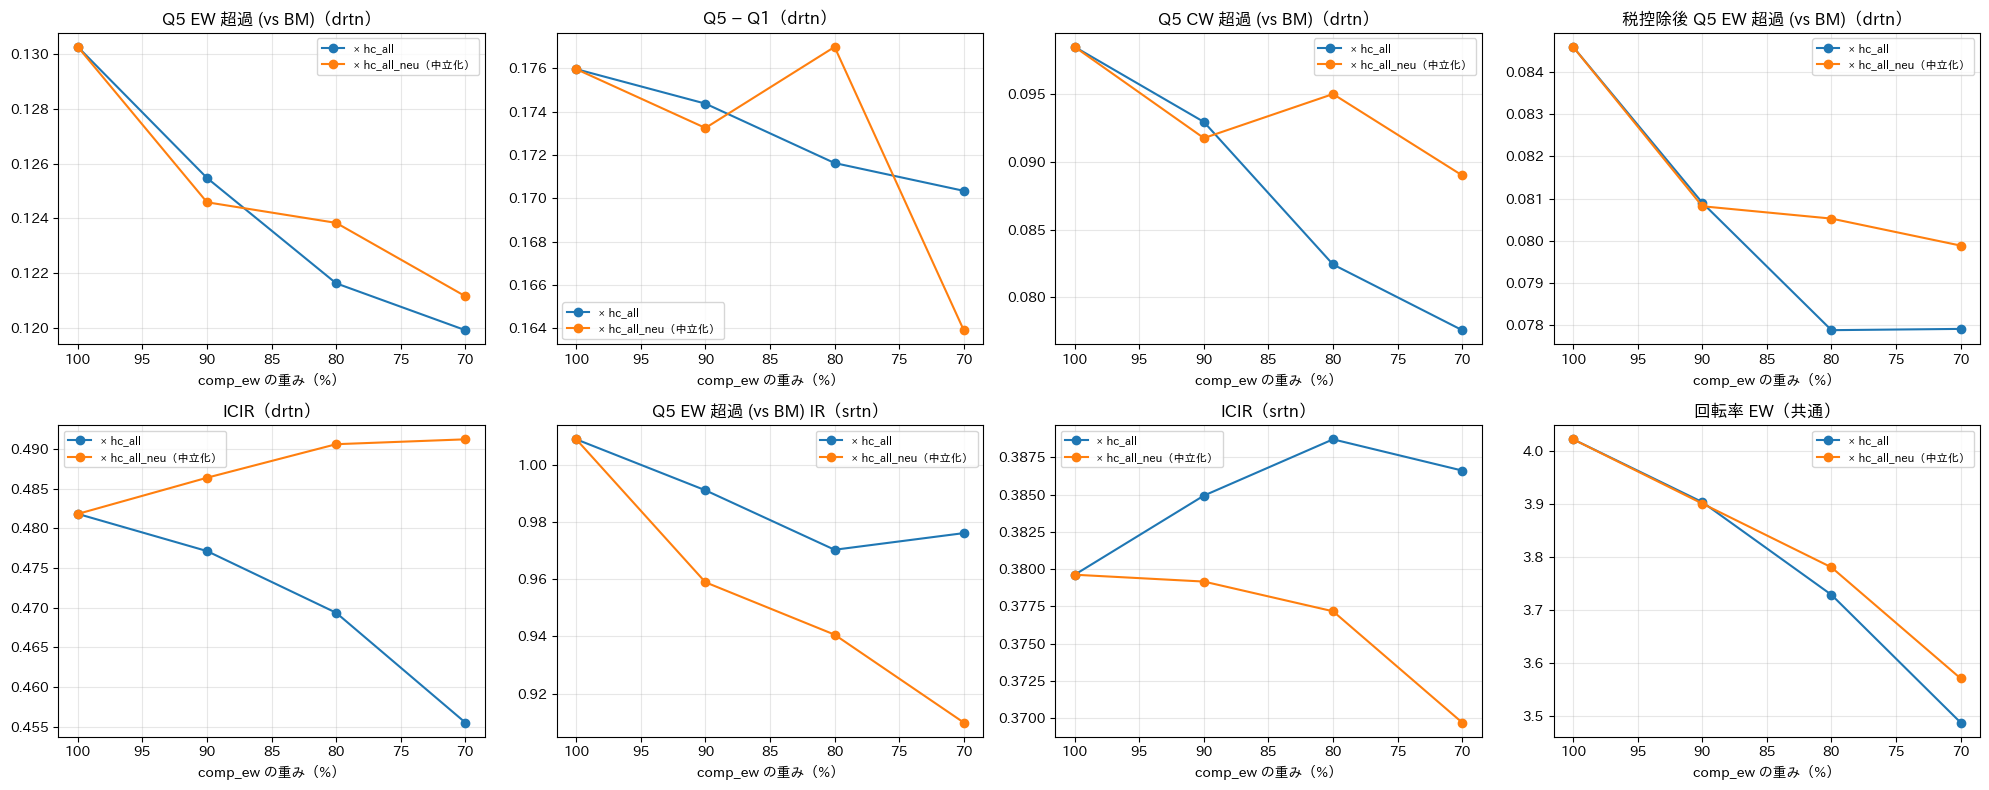

In [6]:
xw = [100] + W
fam = {"× hc_all": ["comp_ew"] + [f"comp_ew_{w}_hc_{100 - w}" for w in W], "× hc_all_neu（中立化）": ["comp_ew"] + [f"comp_ew_{w}_hcneu_{100 - w}" for w in W]}
cols = [("drtn", "Q5 EW 超過 (vs BM)"), ("drtn", "Q5 − Q1"), ("drtn", "Q5 CW 超過 (vs BM)"), ("drtn", "税控除後 Q5 EW 超過 (vs BM)"), ("drtn", "ICIR"), ("srtn", "Q5 EW 超過 (vs BM) IR"), ("srtn", "ICIR"), ("共通", "回転率 EW")]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cols):
    for label, names in fam.items():
        ax.plot(xw, [tbl.loc[n, col] for n in names], marker="o", label=label)
    ax.set_title(f"{col[1]}（{col[0]}）")
    ax.set_xlabel("comp_ew の重み（%）")
    ax.invert_xaxis()
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.4 累積図

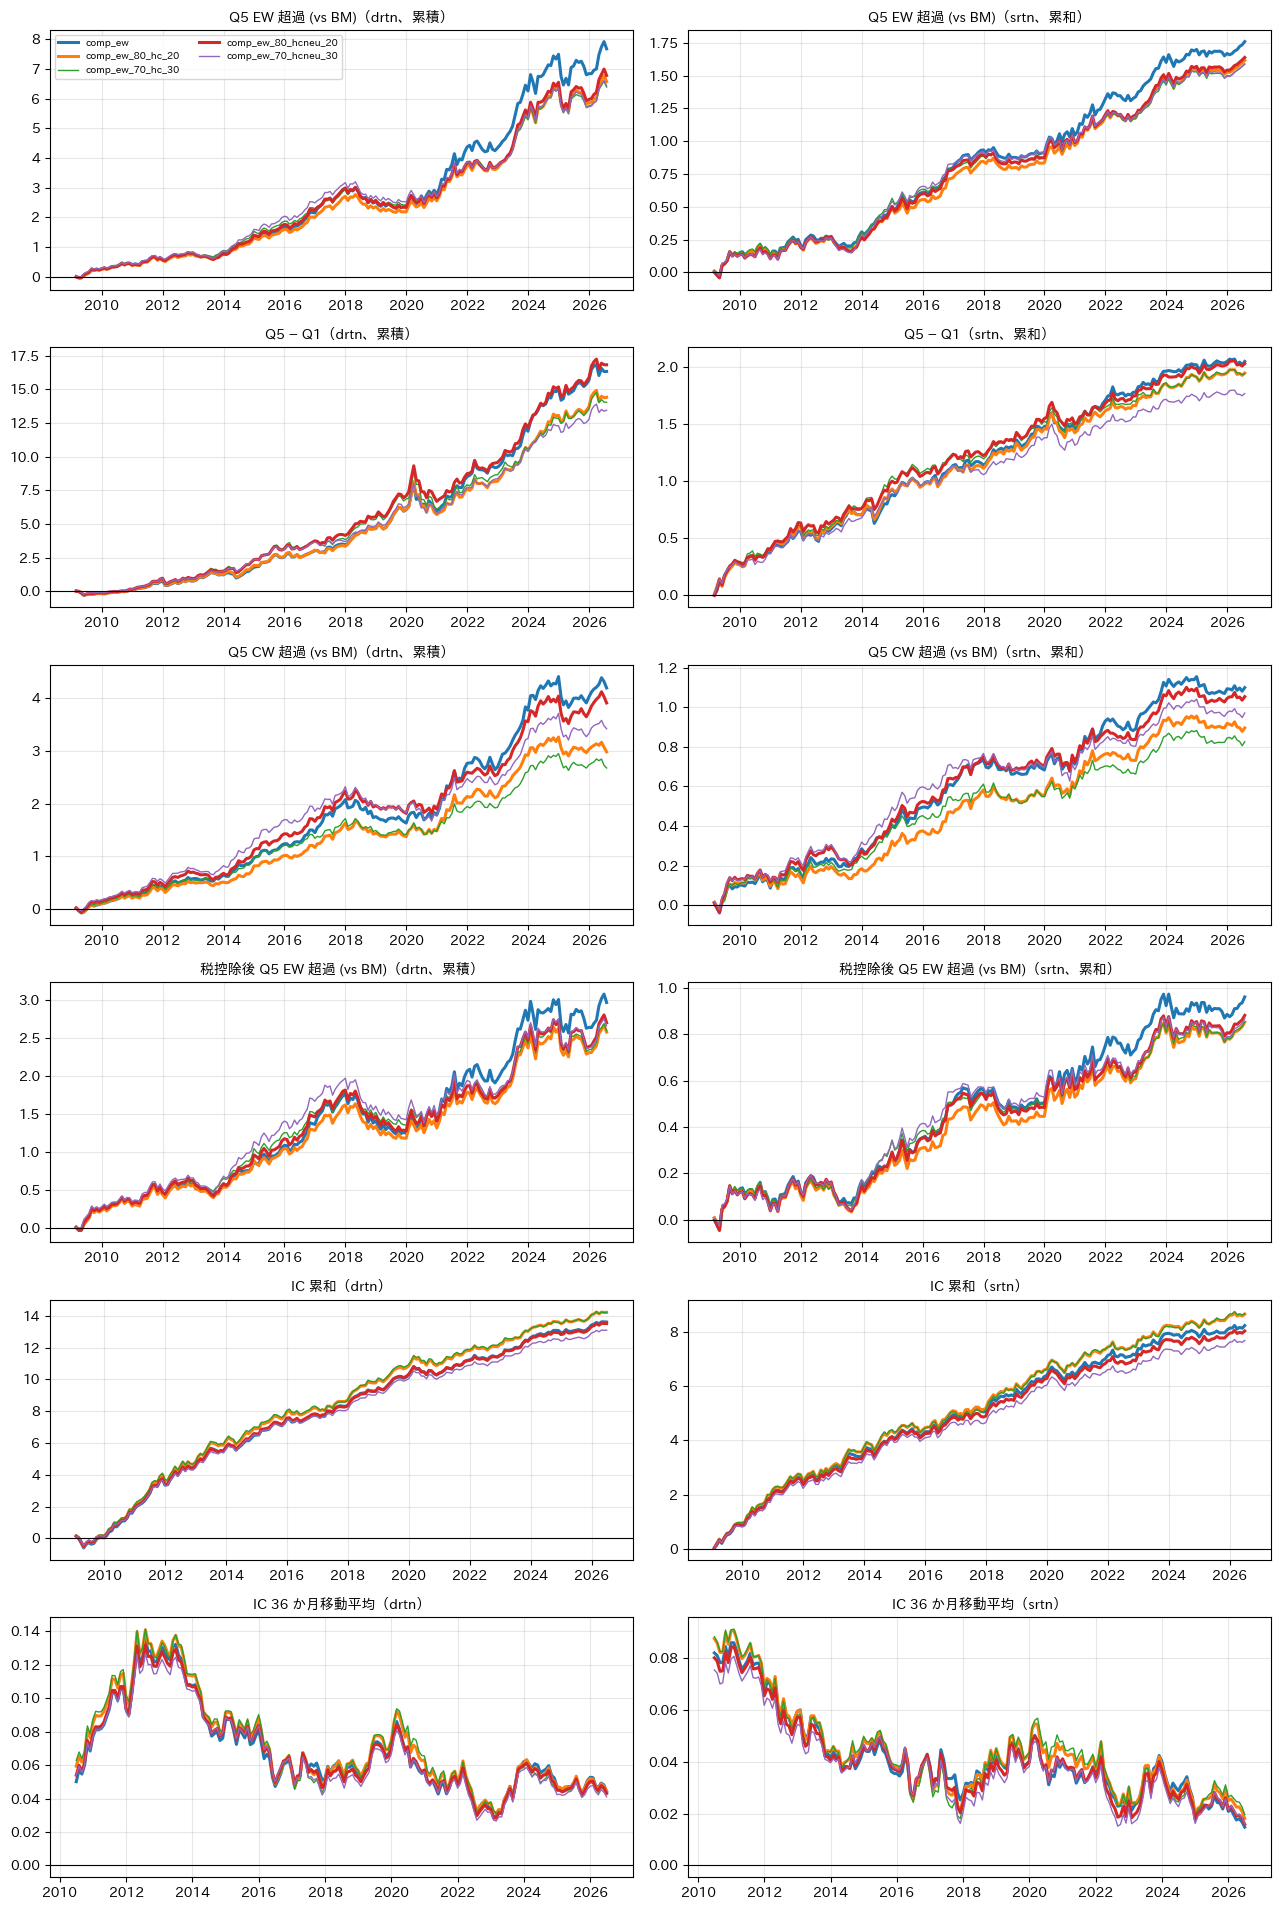

In [7]:
fig = plot_cumulative({n: reports[n] for n in ["comp_ew", "comp_ew_80_hc_20", "comp_ew_70_hc_30", "comp_ew_80_hcneu_20", "comp_ew_70_hcneu_30"]}, highlight=["comp_ew", "comp_ew_80_hc_20", "comp_ew_80_hcneu_20"])
plt.show()

### 3.5 アルファ横断の棒グラフ（年率、IC は平均）

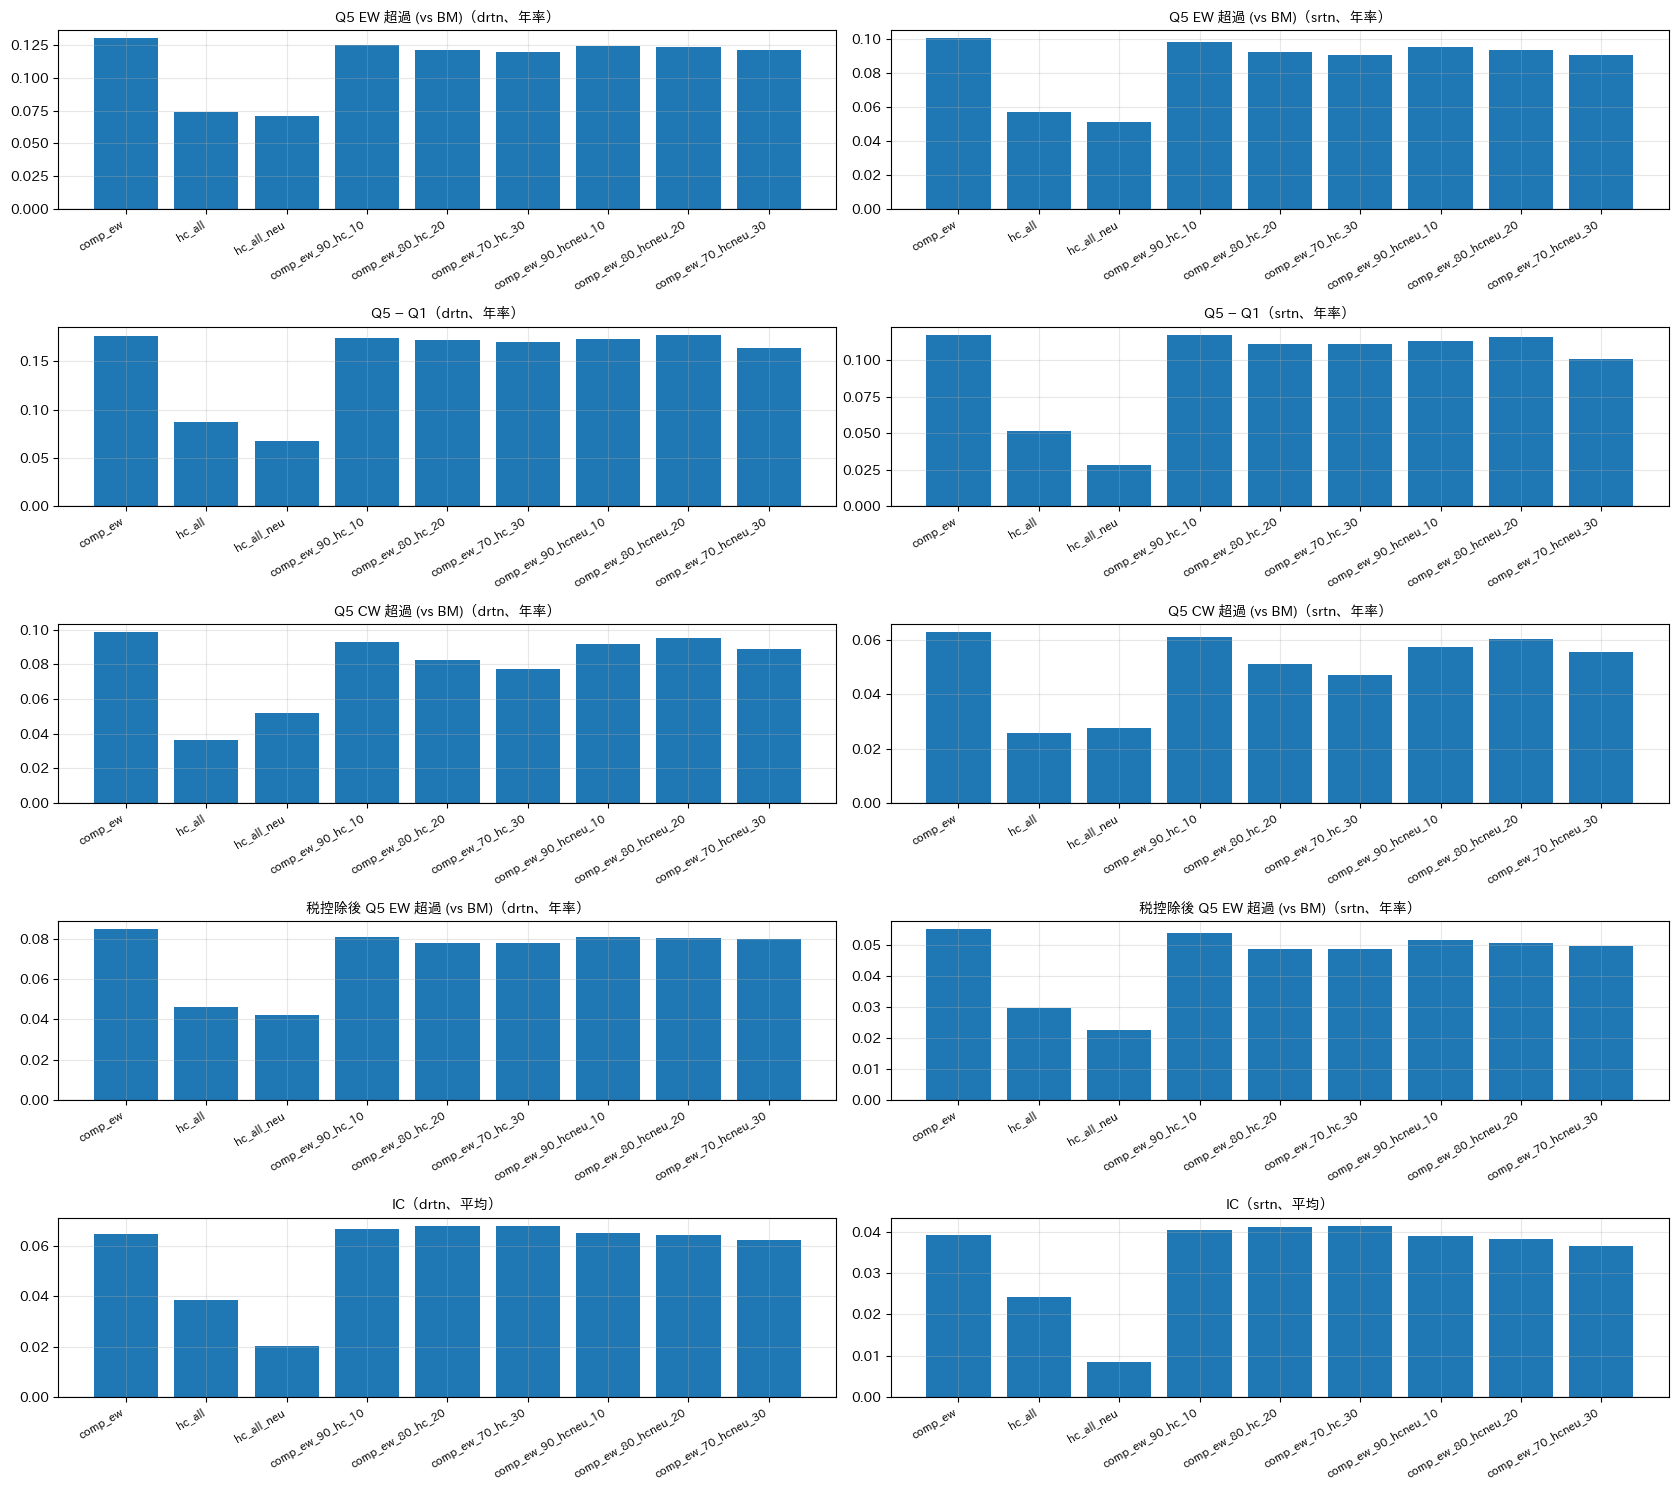

In [8]:
fig = plot_cross_alpha_bars(reports)
plt.show()

### 3.6 期間別（comp_ew 比の差分、srtn）

複合 − comp_ew の Q5 EW 超過・Q5 − Q1（年率）と IC の差。上乗せが特定期間に偏っていないかを見る。

In [9]:
PERIODS = {"2009–2013": ("2009-01", "2013-12"), "2014–2018": ("2014-01", "2018-12"), "2019–2022": ("2019-01", "2022-12"), "2023–2026": ("2023-01", "2026-07")}
base = reports["comp_ew"]
rows = {}
for n in BLENDS:
    rep = reports[n]
    row = {}
    for p, (a, b) in PERIODS.items():
        row[(p, "Δ Q5 EW 超過")] = (rep.series["ew_excess"]["srtn"].loc[a:b].mean() - base.series["ew_excess"]["srtn"].loc[a:b].mean()) * 12
        row[(p, "Δ Q5−Q1")] = (rep.series["spread"]["srtn"].loc[a:b].mean() - base.series["spread"]["srtn"].loc[a:b].mean()) * 12
        row[(p, "Δ IC")] = rep.series["ic"]["srtn"].loc[a:b].mean() - base.series["ic"]["srtn"].loc[a:b].mean()
    rows[n] = row
d = pd.DataFrame(rows).T
d.columns = pd.MultiIndex.from_tuples(d.columns)
display(d.round(3))

2009–2013                 2014–2018                 2019–2022                 2023–2026               
                    Δ Q5 EW 超過 Δ Q5−Q1   Δ IC Δ Q5 EW 超過 Δ Q5−Q1   Δ IC Δ Q5 EW 超過 Δ Q5−Q1   Δ IC Δ Q5 EW 超過 Δ Q5−Q1   Δ IC
comp_ew_90_hc_10        -0.002  -0.003  0.002     -0.002   0.007  0.000     -0.013  -0.019  0.002      0.009   0.015  0.001
comp_ew_80_hc_20        -0.009   0.000  0.003     -0.007  -0.005  0.000     -0.020  -0.023  0.003      0.005   0.005  0.002
comp_ew_70_hc_30        -0.000   0.013  0.003     -0.006  -0.002 -0.000     -0.034  -0.034  0.003     -0.001  -0.007  0.003
comp_ew_90_hcneu_10     -0.009  -0.009 -0.000     -0.001   0.007 -0.001     -0.016  -0.025 -0.000      0.006   0.010  0.000
comp_ew_80_hcneu_20     -0.008   0.012 -0.001      0.001   0.002 -0.002     -0.026  -0.025 -0.001      0.006   0.004  0.000
comp_ew_70_hcneu_30     -0.004  -0.005 -0.004      0.002  -0.016 -0.003     -0.036  -0.029 -0.002     -0.005  -0.018 -0.000

## 所見

**結論: core だけで作れる Healthy Compounder の柱は、comp_ew に上乗せできない。** 複合スコアのファイルは作ってあるが、最適化に回す価値は低い。

**1. 残差 IC は残るが、中身はスタイル。** 統合スコアを comp_ew に回帰した残差の IC は 0.021（t 2.7、srtn でも t 2.4）と残る。
ところがサイズ・`vola60`・セクターで中立化した版では残差 IC がほぼゼロ（t 0.8 / −0.3）になる。comp_ew と独立な部分は、主に低ボラ・大型・セクターの傾きだった。

**2. スパニング回帰ではアルファが残らない。** 統合スコアの Q5 − Q1 は comp_ew の Q5 − Q1 で R² 0.46 説明され、アルファは −2.9%（t −1.1）。
順位相関は 0.29 と低くても、ロングショートのリターンは同じ方向に動いている。5% 水準で正のアルファを持つ素材はなく、
最も大きいのは CF/P の 4.2%（t 1.8）、中立化版の 3.5%（t 1.7）、発行の 2.8%（t 1.1）。QMJ・安全性・成長はむしろ有意に負。

**3. 複合はどの比率でも comp_ew を上回らない。**

| | Q5 EW 超過 | Q5 − Q1 | Q5 CW 超過 | 税後 Q5 EW 超過 | ICIR | 回転率 |
| --- | --- | --- | --- | --- | --- | --- |
| comp_ew | 13.0% | 17.6% | 9.9% | 8.5% | 0.48 | 402% |
| 80:20（hc_all） | 12.2% | 17.2% | 8.2% | 7.8% | 0.47 | 373% |
| 80:20（中立化版） | 12.4% | 17.7% | 9.5% | 8.1% | 0.49 | 378% |

中立化版の 80:20 は Q5 − Q1 と ICIR がわずかに上がるが誤差の範囲で、srtn の指標はすべて下がる。回転率の低下も 7% 程度にとどまる。

**4. 劣後は 2019〜2022 年に集中。** 複合 − comp_ew の srtn Q5 EW 超過は 2019〜2022 年に −1.3〜−3.6%/年で、ほかの期間はほぼゼロ。

**次の一手**
- 差別化はインド固有のデータが要る柱に求める。⑤ガバナンス（担保差入・プロモーター保有・RPT）と、⑥の価格系（52 週高値・オーバーナイト・ID 調整モメンタム。日次ビルダーが必要）。
- §0 で販管費比率が単独で正の IC を持ったので、② の無形資産補正バリュー（Eisfeldt et al. 2022）は core だけで試す価値がある。
- 発行（④）と CF/P は単独のアルファが最も大きいので、comp_ew のスリーブ D に組み込む形の再設計は検討余地がある。